# Individuell uppgift – Hälsostudie

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from scipy import stats

df = pd.read_csv("data/health_study_dataset.csv")

print(df.isna().sum())
print()
print(df.duplicated().sum())
print()
print(df.dtypes)
df.head()

# Can't find anything wrong with the csv file so no cleaning needed

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

0

id               int64
age              int64
sex                str
height         float64
weight         float64
systolic_bp    float64
cholesterol    float64
smoker             str
disease          int64
dtype: object


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [26]:
# calcluates the different values of columns
cols = ["age", "weight", "height", "systolic_bp", "cholesterol"]

df[cols].agg(["mean", "median", "min", "max"]).T.round(2)


,mean,median,min,max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


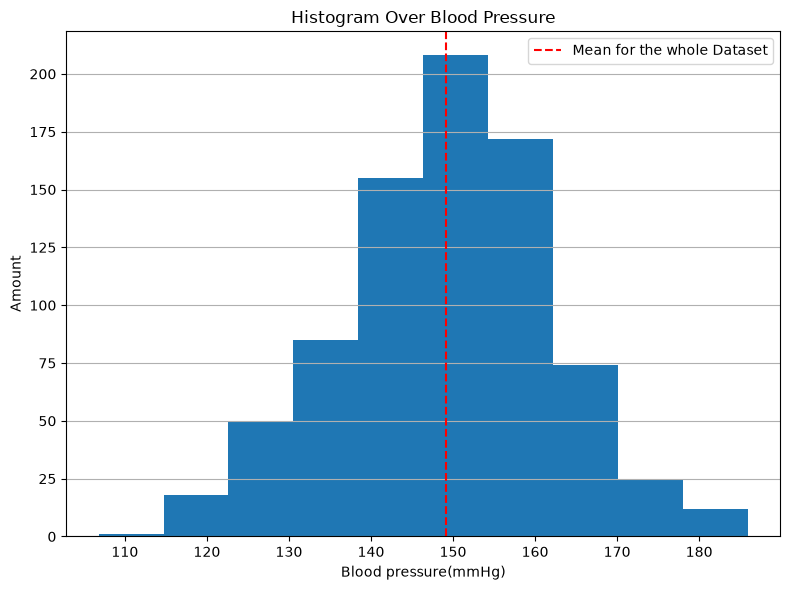

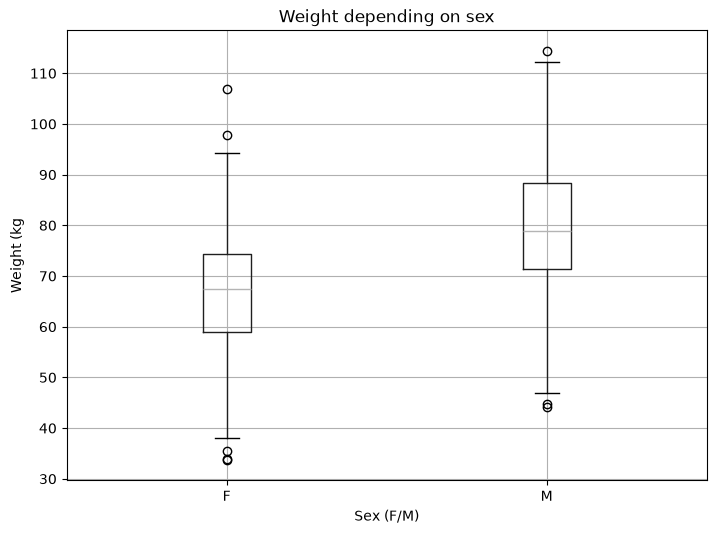

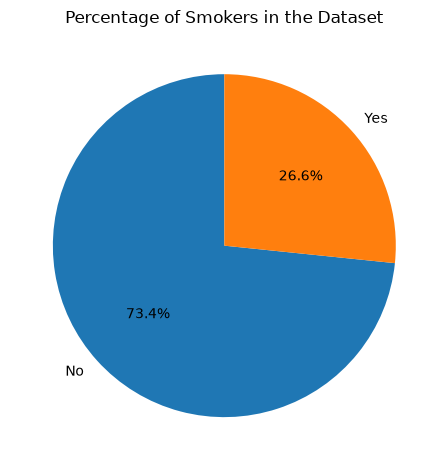

In [27]:
fig, ax = plt.subplots(figsize=(8,6))
ax.hist(df["systolic_bp"])
ax.axvline(df["systolic_bp"].mean(), color="red", linestyle="--", label="Mean for the whole Dataset")
ax.set_title("Histogram Over Blood Pressure")
ax.set_xlabel("Blood pressure(mmHg)")
ax.set_ylabel("Amount")
ax.grid(True, axis="y")
ax.legend()
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(8,6))
df.boxplot(column="weight", by="sex", ax=ax)
plt.suptitle("")
ax.set_title("Weight depending on sex")
ax.set_xlabel("Sex (F/M)")
ax.set_ylabel("Weight (kg")
plt.show()


share_smokers = df["smoker"].value_counts(normalize=True) * 100

fig, ax = plt.subplots()
ax.pie(
    share_smokers.values,
    labels=share_smokers.index,
    autopct="%1.1f%%",
    startangle=90,
)
ax.set_title("Percentage of Smokers in the Dataset")
plt.tight_layout()
plt.show()

In [28]:
# share in %
share_disease = df["disease"].mean() * 100

print(f"The share of people with the disease from the dataset is: {share_disease:.1f} % ")
print()

# check to see if data matches
amount_disease = (df["disease"] == 1).sum()
total_people = len(df)
print(amount_disease, total_people) 



The share of people with the disease from the dataset is: 5.9 % 

47 800


In [29]:
np.random.seed(42)

p = df["disease"].mean()
sim_disease = np.random.binomial(n=1, p=p, size=1000)
sim_share = sim_disease.mean() * 100
diff =  sim_share - share_disease


print(f"Prevalence of disease in dataset: {share_disease:.1f} %")
print(f"Prevalence of disease in simulation: {sim_share:.1f} %")
print(f"Difference between simulation and in dataset: {diff:.1f} (percentage points)")

Prevalence of disease in dataset: 5.9 %
Prevalence of disease in simulation: 5.6 %
Difference between simulation and in dataset: -0.3 (percentage points)


In [30]:
systolic = df["systolic_bp"]

n = len(systolic)
m = systolic.mean()
s = systolic.std(ddof=1)
se = s/ np.sqrt(len(systolic))
z = 1.96

lower = m - z*se
upper = m + z*se

print("Size of the sample:", n)
print("Point estimate (mean):", m)
print(("Sample standard deviation:", s))
print("Standard error:", se)
print(f"95% CI: ({lower:.2f}, {upper:.2f})")

Size of the sample: 800
Point estimate (mean): 149.178625
('Sample standard deviation:', np.float64(12.793360316766597))
Standard error: 0.4523135917074269
95% CI: (148.29, 150.07)


In [31]:
# Signifikansnivå: alfa = 0.05

smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"]
non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"]

t_stat_w, p_val_w = stats.ttest_ind(smokers, non_smokers, equal_var=False, alternative="greater")

print(f"Welch t-test: t = {t_stat_w:.3f}, p = {p_val_w:.4f}")


Welch t-test: t = 0.450, p = 0.3264


- teststatistiken är 0.450 vilket är ganska litet och inte ovanligt
- p-värdet är 0.3264. Vilket är > alpha. Därför förkastar vi inte H0.
- Vi har inte tillräckligt stöd för att rökare har högre medelblodtryck än icke-rökare.